# Arbitrary transducer arrays and the JAX backend

This notebook covers:
1. Defining an **arbitrary 2-D array** as $(x, z)$ points and an **arbitrary 3-D array** as $(x, y, z)$ points, both in `param.elements`.
2. Viewing both arrays in an **interactive 3-D plot** (`pymust.utils.plot_transducer_array`).
3. Running the simulators and beamformers with the **JAX backend**: `options.Backend = "jax"` for `pfield`, `pfield3`, `simus` and `simus3`, and `backend="jax"` for `dasmtx` and `applyDasMTX`.

The JAX path matches the default numpy path to about 1e-6 relative, as the comparisons below show.

It needs the optional extras: `pip install pymust[jax,plot]`.

**Note:** the delays in this notebook come from `txdelay`/`txdelay3`. Their tilt equations and delay profiles for non-planar, irregular or off-centre arrays are **still to be verified** against an independent reference such as MATLAB MUST or the beam direction in simulated fields. See `docs/transducer_array_support.md`, §6.5.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pymust
from pymust.utils import Options, Param, plot_transducer_array

M_TO_MM = 1e3

def time_backends(compute):
    """Run compute(backend) for numpy and jax and return both results.

    The jax call is made twice, so its timing excludes the one-off compilation.
    """
    results, timings_s = {}, {}
    for backend in ("numpy", "jax"):
        if backend == "jax":
            compute(backend)
        start = time.perf_counter()
        results[backend] = compute(backend)
        timings_s[backend] = time.perf_counter() - start
    relative_difference = np.max(np.abs(np.asarray(results["jax"]) - np.asarray(results["numpy"]))) / np.max(np.abs(results["numpy"]))
    print(f"numpy {timings_s['numpy']:.2f} s | jax {timings_s['jax']:.2f} s | max relative difference {relative_difference:.1e}")
    return results

## 1. An arbitrary 2-D array: 96 elements on a wavy line

The 2-D functions (`txdelay`, `pfield`, `simus`, `dasmtx`, ...) work in the $x$–$z$ plane. An array is just its element centres: a 2-row `elements` array of $(x, z)$ points. No `pitch`, `Nelements` or `radius` is needed. Each element still needs a `width`, and its normal points along $+z$.

In [2]:
NUM_ELEMENTS_2D = 96
element_x = (np.arange(NUM_ELEMENTS_2D) - (NUM_ELEMENTS_2D - 1) / 2) * 300e-6
element_z = 0.5e-3 * np.sin(2 * np.pi * element_x / 10e-3)          # 0.5 mm ripple, 10 mm period

param_2d = Param(fc=5e6, fs=20e6, bandwidth=75, width=250e-6, height=5e-3, focus=30e-3,
                 elements=np.stack([element_x, element_z]))          # (x, z) points
print(param_2d.elements.shape)

(2, 96)


The viewer reads 2-row `elements` as $(x, y)$, the 3-D convention. To see the depth ripple, pass the same points as 3 rows $(x, 0, z)$. The 2-D functions accept that form as well. Drag to rotate the view and hover over an element to see its index.

In [3]:
param_2d_view = param_2d.copy()
param_2d_view.elements = np.stack([element_x, np.zeros_like(element_x), element_z])
plot_transducer_array(param_2d_view)

### Pressure field: numpy vs JAX
The plane-wave delays include the element depths ($\tau_e = (x_e\sin\theta + z_e\cos\theta)/c$), so the ripple is compensated and the transmitted wavefront is flat.

numpy 1.36 s | jax 0.94 s | max relative difference 5.7e-07


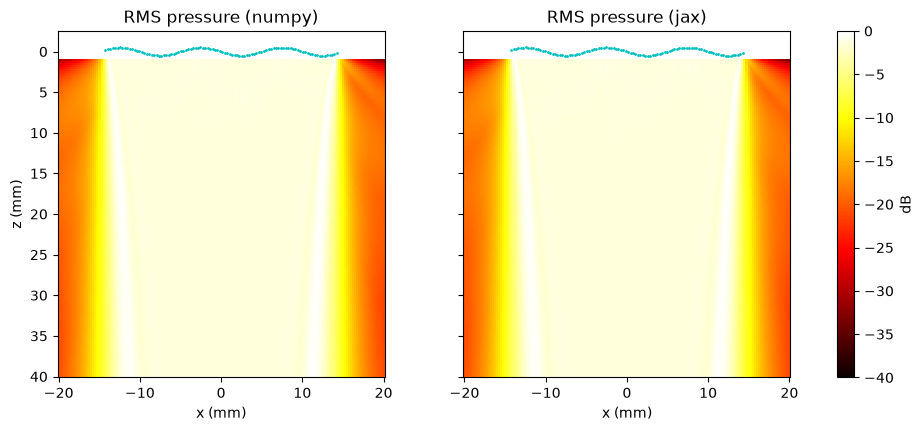

In [4]:
delays_2d = pymust.txdelay(param_2d.copy(), 0.0)
x_grid, z_grid = np.meshgrid(np.linspace(-20e-3, 20e-3, 160), np.linspace(1e-3, 40e-3, 160))

fields = time_backends(lambda backend: pymust.pfield(x_grid, None, z_grid, delays_2d, param_2d.copy(), Options(Backend=backend))[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, backend in zip(axes, fields):
    pressure_db = 20 * np.log10(fields[backend] / fields[backend].max())
    image = ax.pcolormesh(x_grid * M_TO_MM, z_grid * M_TO_MM, pressure_db, vmin=-40, shading="auto", cmap="hot")
    ax.plot(element_x * M_TO_MM, element_z * M_TO_MM, "c.", markersize=2)
    ax.set(title=f"RMS pressure ({backend})", xlabel="x (mm)", aspect="equal")
axes[0].set_ylabel("z (mm)"); axes[0].invert_yaxis()
fig.colorbar(image, ax=axes, label="dB")

### Full imaging chain on the JAX backend
The chain runs `simus` → `rf2iq` → `dasmtx` → `applyDasMTX` → `bmode`, and every step uses the same arbitrary element positions.

simus + rf2iq + dasmtx + DAS on JAX: 1.2 s, RF shape (1226, 96)


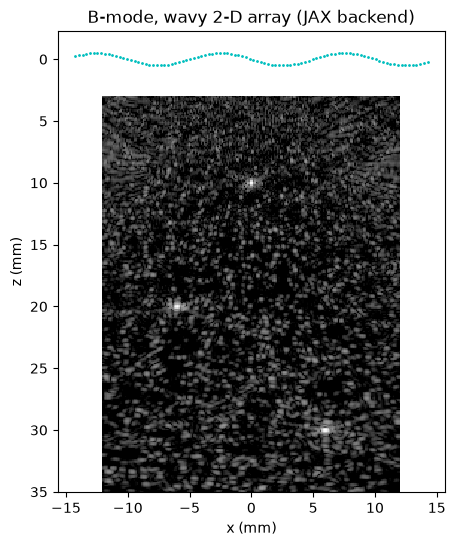

In [5]:
rng = np.random.default_rng(0)
num_scatterers = 3000
scatterer_x = rng.uniform(-12e-3, 12e-3, num_scatterers)
scatterer_z = rng.uniform(3e-3, 35e-3, num_scatterers)
reflectivity = rng.rayleigh(1, num_scatterers)
scatterer_x = np.append(scatterer_x, [0.0, -6e-3, 6e-3])               # three bright points
scatterer_z = np.append(scatterer_z, [10e-3, 20e-3, 30e-3])
reflectivity = np.append(reflectivity, [30.0, 30.0, 30.0])

start = time.perf_counter()
rf, _ = pymust.simus(scatterer_x, np.zeros_like(scatterer_x), scatterer_z, reflectivity, delays_2d, param_2d, Options(Backend="jax"))
iq = pymust.rf2iq(rf, param_2d)
x_image, z_image = np.meshgrid(np.linspace(-12e-3, 12e-3, 200), np.linspace(3e-3, 35e-3, 300))
das_matrix = pymust.dasmtx(iq, x_image, z_image, delays_2d, param_2d, backend="jax")
beamformed_iq = pymust.utils.applyDasMTX(das_matrix, iq, x_image.shape, backend="jax")
print(f"simus + rf2iq + dasmtx + DAS on JAX: {time.perf_counter() - start:.1f} s, RF shape {rf.shape}")

plt.figure(figsize=(5, 6))
plt.pcolormesh(x_image * M_TO_MM, z_image * M_TO_MM, pymust.bmode(beamformed_iq, 40), cmap="gray", shading="auto")
plt.plot(element_x * M_TO_MM, element_z * M_TO_MM, "c.", markersize=2)
plt.gca().set(title="B-mode, wavy 2-D array (JAX backend)", xlabel="x (mm)", ylabel="z (mm)", aspect="equal")
plt.gca().invert_yaxis()

## 2. An arbitrary 3-D array: a spiral on a spherical cap

The 3-D functions (`txdelay3`, `pfield3`, `simus3`, `dasmtx3`) take a 3-row `elements` array of $(x, y, z)$ points. Here 128 elements follow a Fermat spiral, a common sparse-array layout, and are placed on a spherical cap of radius 30 mm.

In [6]:
NUM_ELEMENTS_3D = 128
CAP_RADIUS_M = 30e-3
APERTURE_RADIUS_M = 6e-3
GOLDEN_ANGLE_RAD = np.pi * (3 - np.sqrt(5))

spiral_index = np.arange(NUM_ELEMENTS_3D)
radial_m = APERTURE_RADIUS_M * np.sqrt((spiral_index + 0.5) / NUM_ELEMENTS_3D)
angle_rad = spiral_index * GOLDEN_ANGLE_RAD
spiral_x = radial_m * np.cos(angle_rad)
spiral_y = radial_m * np.sin(angle_rad)
spiral_z = CAP_RADIUS_M - np.sqrt(CAP_RADIUS_M**2 - radial_m**2)

param_3d = Param(fc=3e6, fs=12e6, bandwidth=70, width=500e-6, height=500e-6,
                 elements=np.stack([spiral_x, spiral_y, spiral_z]))   # (x, y, z) points
plot_transducer_array(param_3d, thickness=500e-6)

### Focused transmit: delays and pressure field, numpy vs JAX
The focused delays use the full 3-D distance from each element to the focus, including the cap depth $z_e$. The field is computed in the $x$–$z$ plane at $y = 0$.

numpy 0.74 s | jax 0.55 s | max relative difference 2.7e-07


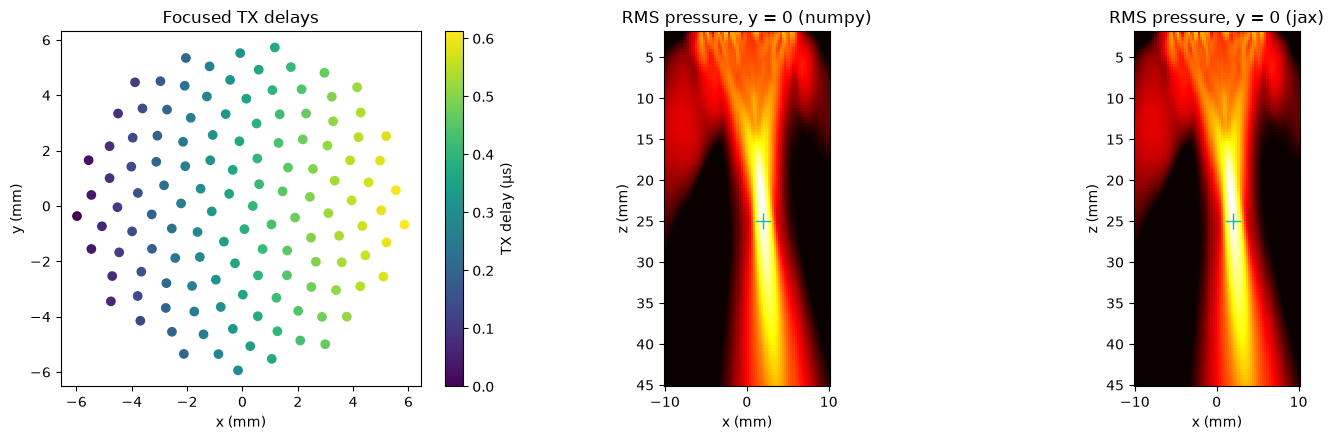

In [7]:
FOCUS_M = (2e-3, 0.0, 25e-3)
delays_3d = pymust.txdelay3(*FOCUS_M, param_3d.copy())

x_grid, z_grid = np.meshgrid(np.linspace(-10e-3, 10e-3, 80), np.linspace(2e-3, 45e-3, 120))
y_grid = np.zeros_like(x_grid)
fields_3d = time_backends(lambda backend: pymust.pfield3(x_grid, y_grid, z_grid, delays_3d, param_3d.copy(), Options(Backend=backend))[0])

fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(1, 3, 1)
points = ax.scatter(spiral_x * M_TO_MM, spiral_y * M_TO_MM, c=delays_3d.ravel() * 1e6, cmap="viridis")
fig.colorbar(points, ax=ax, label="TX delay (µs)")
ax.set(title="Focused TX delays", xlabel="x (mm)", ylabel="y (mm)", aspect="equal")
for index, backend in enumerate(fields_3d, start=2):
    ax = fig.add_subplot(1, 3, index)
    pressure_db = 20 * np.log10(fields_3d[backend] / fields_3d[backend].max())
    ax.pcolormesh(x_grid * M_TO_MM, z_grid * M_TO_MM, pressure_db, vmin=-30, shading="auto", cmap="hot")
    ax.plot(FOCUS_M[0] * M_TO_MM, FOCUS_M[2] * M_TO_MM, "c+", markersize=12)
    ax.set(title=f"RMS pressure, y = 0 ({backend})", xlabel="x (mm)", ylabel="z (mm)", aspect="equal")
    ax.invert_yaxis()
fig.tight_layout()

### RF echoes from three point scatterers along the focused beam, with `simus3` on JAX

numpy 0.01 s | jax 0.00 s | max relative difference 7.4e-07


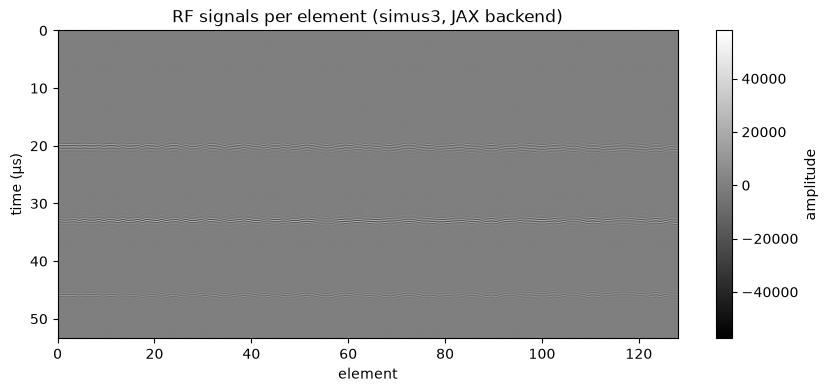

In [8]:
point_z = np.array([15e-3, 25e-3, 35e-3])
point_x = FOCUS_M[0] * point_z / FOCUS_M[2]          # on the line from the array centre to the focus
point_y = np.zeros(3)
rf_3d = time_backends(lambda backend: pymust.simus3(point_x, point_y, point_z, np.ones(3), delays_3d, param_3d.copy(), Options(Backend=backend))[0])

time_us = np.arange(rf_3d["jax"].shape[0]) / param_3d.fs * 1e6
plt.figure(figsize=(10, 4))
plt.imshow(rf_3d["jax"], aspect="auto", cmap="gray", extent=[0, NUM_ELEMENTS_3D, time_us[-1], 0])
plt.gca().set(title="RF signals per element (simus3, JAX backend)", xlabel="element", ylabel="time (µs)")
plt.colorbar(label="amplitude")

## 3. Any 3-D point set: explicit x, y and z coordinates

`elements` is just three coordinate rows, so any point set works. This example uses an irregular array of 64 elements:
- an 8×8 grid with 1.2 mm pitch;
- every element moved randomly by up to ±0.3 mm in $x$ and $y$;
- every element set at a random depth between 0 and 1.5 mm.

`txdelay3` focuses the transmit at a point off the array axis. `pfield3` (on the JAX backend) then gives the beamformed RMS pressure in three orthogonal planes through the focus.

In [9]:
rng = np.random.default_rng(7)
grid_m = (np.arange(8) - 3.5) * 1.2e-3
grid_x, grid_y = (grid.ravel() for grid in np.meshgrid(grid_m, grid_m))
element_x = grid_x + rng.uniform(-0.3e-3, 0.3e-3, grid_x.size)   # x coordinates (m)
element_y = grid_y + rng.uniform(-0.3e-3, 0.3e-3, grid_y.size)   # y coordinates (m)
element_z = rng.uniform(0.0, 1.5e-3, grid_x.size)                # z coordinates (m)

param_irregular = Param(fc=3e6, fs=12e6, bandwidth=70, width=600e-6, height=600e-6,
                        elements=np.stack([element_x, element_y, element_z]))
plot_transducer_array(param_irregular)

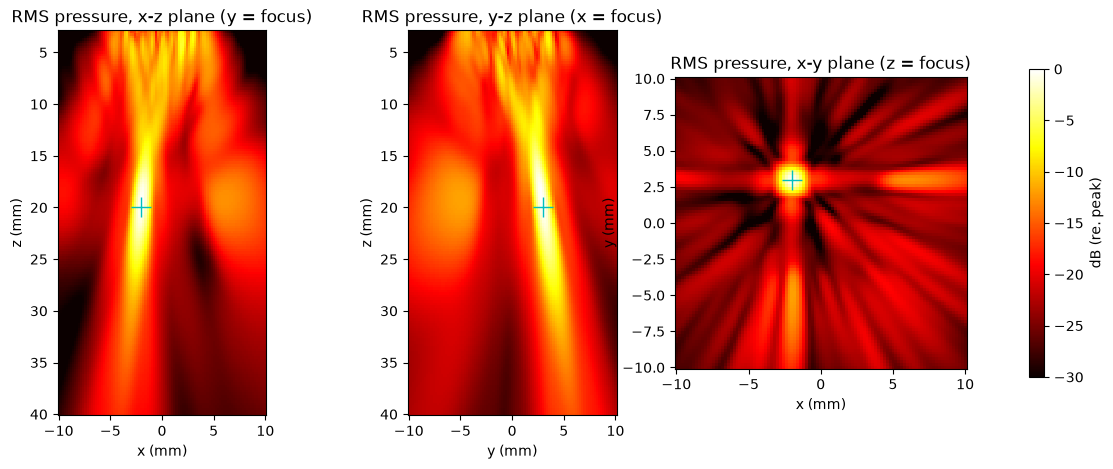

In [10]:
FOCUS_IRREGULAR_M = np.array([-2e-3, 3e-3, 20e-3])
delays_irregular = pymust.txdelay3(*FOCUS_IRREGULAR_M, param_irregular.copy())
jax_options = Options(Backend="jax")

def compute_rms_pressure(x, y, z):
    return pymust.pfield3(x, y, z, delays_irregular, param_irregular.copy(), jax_options)[0]

focus_x, focus_y, focus_z = FOCUS_IRREGULAR_M
lateral_m = np.linspace(-10e-3, 10e-3, 101)
depth_m = np.linspace(3e-3, 40e-3, 150)
planes = {
    "x-z plane (y = focus)": np.meshgrid(lateral_m, focus_y, depth_m, indexing="ij"),
    "y-z plane (x = focus)": np.meshgrid(focus_x, lateral_m, depth_m, indexing="ij"),
    "x-y plane (z = focus)": np.meshgrid(lateral_m, lateral_m, focus_z, indexing="ij"),
}
pressures = {name: compute_rms_pressure(*(axis.squeeze() for axis in grid)) for name, grid in planes.items()}
peak = max(pressure.max() for pressure in pressures.values())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, (x, y, z)) in zip(axes, planes.items()):
    horizontal, vertical, focus_marker = {
        "x-z plane (y = focus)": (x, z, (focus_x, focus_z)),
        "y-z plane (x = focus)": (y, z, (focus_y, focus_z)),
        "x-y plane (z = focus)": (x, y, (focus_x, focus_y)),
    }[name]
    pressure_db = 20 * np.log10(pressures[name] / peak)
    image = ax.pcolormesh(horizontal.squeeze() * M_TO_MM, vertical.squeeze() * M_TO_MM, pressure_db,
                          vmin=-30, vmax=0, shading="auto", cmap="hot")
    ax.plot(focus_marker[0] * M_TO_MM, focus_marker[1] * M_TO_MM, "c+", markersize=14)
    axis_names = name.split()[0].split("-")
    ax.set(title=f"RMS pressure, {name}", xlabel=f"{axis_names[0]} (mm)", ylabel=f"{axis_names[1]} (mm)", aspect="equal")
    if axis_names[1] == "z":
        ax.invert_yaxis()
fig.colorbar(image, ax=axes, label="dB (re. peak)", shrink=0.8)